In [12]:
# !pip install ultralytics

In [1]:
!nvidia-smi

Fri Nov 20 08:35:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import gradio as gr

gr.close_all()

In [3]:
import urllib.request
import zipfile
import os

# Dataset URL
url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

# Download location
zip_path = "coco128.zip"

# Download dataset
print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)
print("Download completed!")

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("datasets")

print("Dataset extracted successfully!")

# Remove ZIP file
os.remove(zip_path)

Download completed!
Dataset extracted successfully!


In [4]:
image_dir = "datasets/coco128/images/train2017"
label_dir = "datasets/coco128/labels/train2017"

print("Total Images:", len(os.listdir(image_dir)))
print("Total Labels:", len(os.listdir(label_dir)))

Total Images: 128
Total Labels: 128


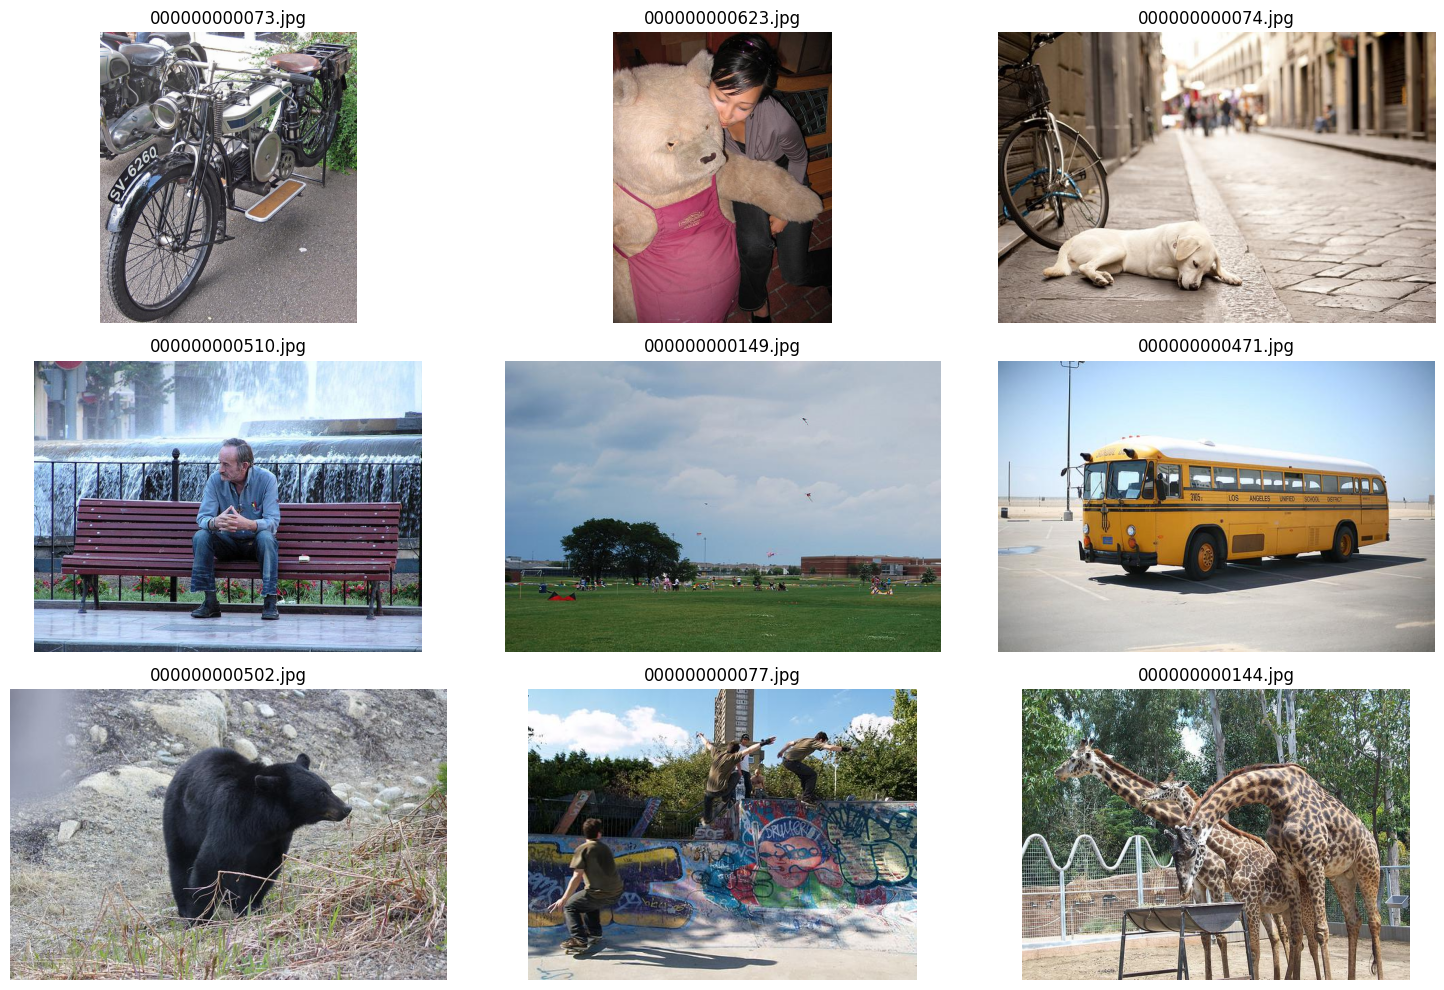

In [5]:
import matplotlib.pyplot as plt
import random

images = random.sample(os.listdir(image_dir), 9)

plt.figure(figsize=(15, 10))

for i, filename in enumerate(images):
    img = plt.imread(os.path.join(image_dir, filename))

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

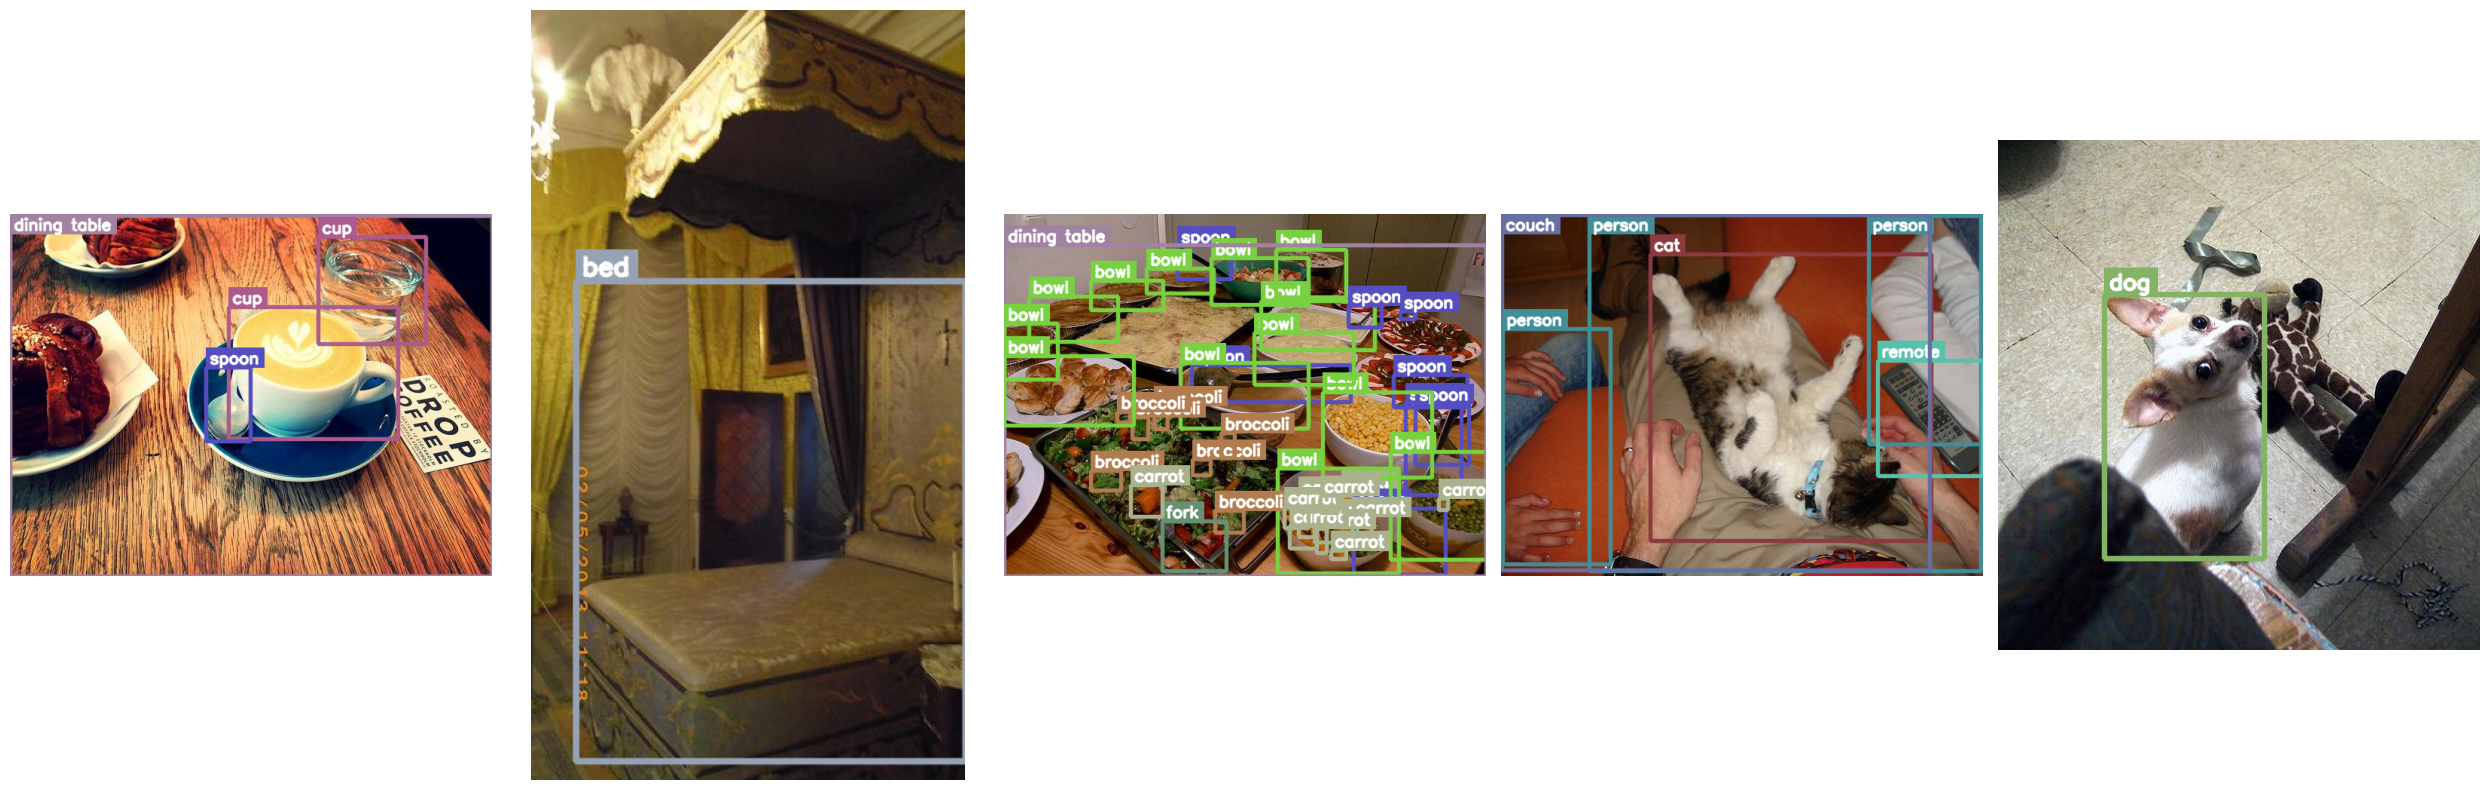

In [7]:
import cv2
import os
import random
import numpy as np
import matplotlib.pyplot as plt

image_dir = "datasets/coco128/images/train2017"
label_dir = "datasets/coco128/labels/train2017"

# Generate consistent colors for each class
np.random.seed(42)
colors = np.random.randint(50, 220, size=(80, 3))

# Select 5 random images
images = random.sample(os.listdir(image_dir), 5)

plt.figure(figsize=(25, 8))

for i, filename in enumerate(images):

    img = cv2.imread(os.path.join(image_dir, filename))
    H, W = img.shape[:2]

    label_file = os.path.splitext(filename)[0] + ".txt"
    label_path = os.path.join(label_dir, label_file)

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:

                cls, xc, yc, w, h = map(float, line.split())
                cls = int(cls)

                color = tuple(map(int, colors[cls]))
                text = class_names[cls]

                # Convert normalized coordinates to pixels
                x1 = int((xc - w / 2) * W)
                y1 = int((yc - h / 2) * H)
                x2 = int((xc + w / 2) * W)
                y2 = int((yc + h / 2) * H)

                # Draw bounding box
                cv2.rectangle(img, (x1, y1), (x2, y2),
                              color, 3, cv2.LINE_AA)

                # Text configuration
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 0.7
                thickness = 2
                padding = 5

                # Calculate text dimensions
                (tw, th), baseline = cv2.getTextSize(
                    text, font, font_scale, thickness
                )

                text_y = max(y1, th + 2 * padding)

                # Draw filled label background
                cv2.rectangle(
                    img,
                    (x1, text_y - th - 2 * padding),
                    (x1 + tw + 2 * padding, text_y),
                    color,
                    -1
                )

                # Draw bold white text
                cv2.putText(
                    img, text,
                    (x1 + padding, text_y - padding),
                    font, font_scale,
                    (255, 255, 255),
                    thickness, cv2.LINE_AA
                )

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import os
import shutil
from sklearn.model_selection import train_test_split

image_dir = "datasets/coco128/images/train2017"
label_dir = "datasets/coco128/labels/train2017"

images = sorted(os.listdir(image_dir))

train, temp = train_test_split(
    images, test_size=0.2, random_state=42
)

val, test = train_test_split(
    temp, test_size=0.5, random_state=42
)

for split, files in zip(
    ["train", "val", "test"], [train, val, test]
):

    os.makedirs(f"dataset/images/{split}", exist_ok=True)
    os.makedirs(f"dataset/labels/{split}", exist_ok=True)

    for filename in files:

        shutil.copy(
            os.path.join(image_dir, filename),
            f"dataset/images/{split}/{filename}"
        )

        label = os.path.splitext(filename)[0] + ".txt"

        if os.path.exists(os.path.join(label_dir, label)):
            shutil.copy(
                os.path.join(label_dir, label),
                f"dataset/labels/{split}/{label}"
            )

print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))

Training: 102
Validation: 13
Testing: 13


In [9]:
import torch

device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: 0
GPU: Tesla T4


In [13]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.info()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

In [15]:
from pathlib import Path
import yaml

dataset_path = Path("./dataset")

dataset_path.mkdir(parents=True, exist_ok=True)

class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

data = {
    "path": str(dataset_path),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_file = dataset_path / "data.yaml"

with open(yaml_file, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(f"YAML file created successfully: {yaml_file}")
print(f"Total classes: {len(class_names)}")

YAML file created successfully: dataset/data.yaml
Total classes: 80


In [19]:
results = model.train(
    data=os.path.abspath("dataset/data.yaml"),
    epochs=30,
    imgsz=640,
    batch=16,
    device=device,
    workers=0,
    project="object_detection",
    name="coco128",
    exist_ok=True,
    plots=True
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/object_detection/coco128/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coco128, nb

In [21]:
model = YOLO(
    "./runs/detect/object_detection/coco128/weights/best.pt"
)

metrics = model.val(
    data=os.path.abspath("dataset/data.yaml"),
    split="test",
    workers=0
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1964.9±493.0 MB/s, size: 67.7 KB)
val: Scanning /content/dataset/labels/test... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 1.5Kit/s 0.0s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.0it/s 0.3s
                   all         13         78      0.505      0.697      0.782      0.574
                person          7         14      0.873      0.982      0.986      0.752
                   car          2          2      0.367        0.5      0.495      0.346
            motorcycle          1          2      0.692          1      0.995      0.795
                 truck          1          1       0.71          1      0.995      0.697

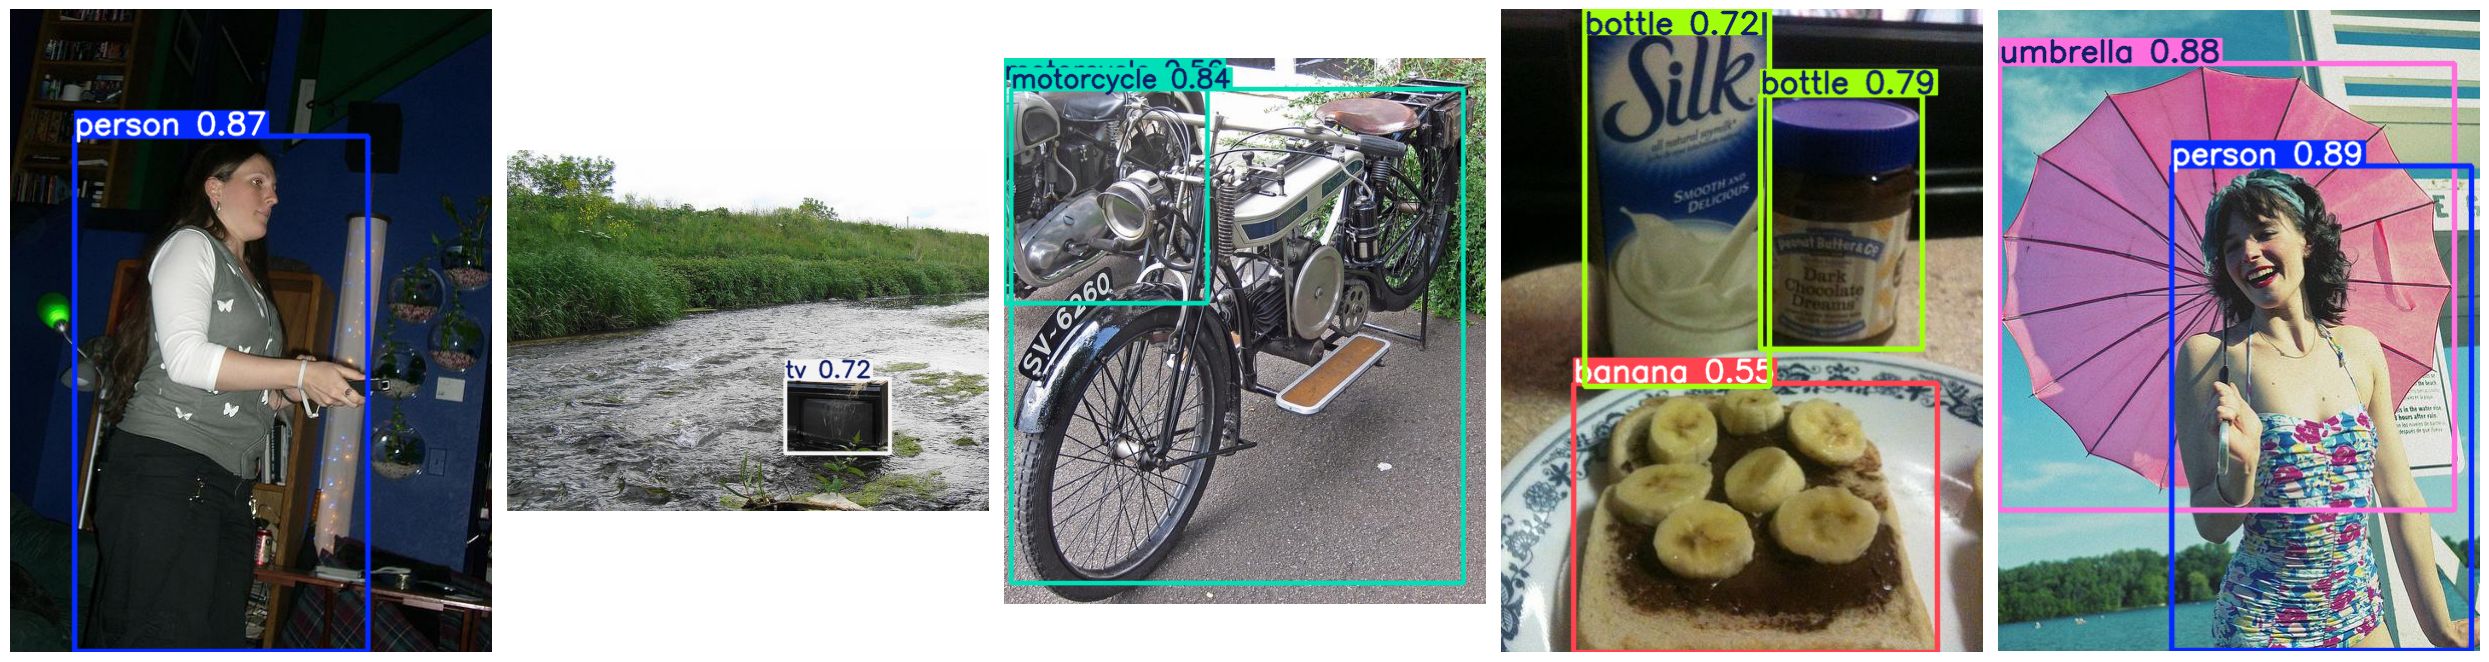

In [22]:
import random
import cv2
import matplotlib.pyplot as plt

test_dir = "dataset/images/test"

images = random.sample(os.listdir(test_dir), 5)

plt.figure(figsize=(25, 8))

for i, filename in enumerate(images):

    results = model.predict(
        source=os.path.join(test_dir, filename),
        conf=0.4,
        verbose=False
    )

    img = results[0].plot(
        line_width=3,
        font_size=18
    )

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import gradio as gr

gr.close_all()

In [24]:
import os
import tempfile
from pathlib import Path

temp_dir = str(Path.home() / "gradio_temp")

os.makedirs(temp_dir, exist_ok=True)

os.environ["GRADIO_TEMP_DIR"] = temp_dir
os.environ["TMPDIR"] = temp_dir
os.environ["TEMP"] = temp_dir
os.environ["TMP"] = temp_dir

tempfile.tempdir = temp_dir

import gradio as gr
import gradio.routes

# Override the internal directory causing the error
gradio.routes.DEFAULT_TEMP_DIR = temp_dir

print("Gradio Version:", gr.__version__)
print("Temporary Directory:", gradio.routes.DEFAULT_TEMP_DIR)
print("Writable:", os.access(temp_dir, os.W_OK))

Gradio Version: 6.31.0
Temporary Directory: /root/gradio_temp
Writable: True


In [25]:
import gradio as gr
import cv2

def predict_image(image):

    results = model.predict(
        source=image,
        conf=0.4,
        iou=0.5,
        save=False
    )

    # Generate image with bounding boxes
    output_image = results[0].plot()

    # Convert BGR to RGB
    output_image = cv2.cvtColor(
        output_image, cv2.COLOR_BGR2RGB
    )

    return output_image


demo = gr.Interface(
    fn=predict_image,

    inputs=gr.Image(
        type="pil",
        label="Upload Image"
    ),

    outputs=gr.Image(
        type="numpy",
        label="Detected Objects"
    ),

    title="AI Object Detection System",
    description="Upload an image to detect objects using YOLO."
)

demo.launch(
    server_name="127.0.0.1",
    server_port=7860
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9d4fea439f2e5eaa05.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
